# 03 — Copy-move por correlação normalizada

Na adulteração do tipo CPI, um trecho do próprio recibo (um caractere, uma palavra) é copiado e colado em outro ponto do mesmo documento. É o tipo mais frequente do dataset. A ELA e o JPEG Ghost não foram pensados para esse caso, porque o trecho colado tem o mesmo histórico de compressão do resto do documento.

Este notebook usa a correlação normalizada, o filtro casado visto em aula (slides 260-272 do material da disciplina): a região suspeita é usada como máscara e comparada com cada posição da imagem. Se ela foi copiada de outro ponto do documento, a correlação com esse ponto fica próxima de 1. Texto autêntico também se repete (o mesmo dígito impresso várias vezes), mas impressão e digitalização não produzem cópias idênticas, e a correlação tende a ficar abaixo da de uma cópia exata.

A fundamentação teórica está em [`report/fundamentacao_copy_move.md`](../report/fundamentacao_copy_move.md).

In [1]:
import sys
sys.path.append("../src")

import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

from copy_move import copy_move_region_score, locate_peaks, visualize_copy_move
from dataset_loader import load_dataset
from evaluation import evaluate_region_technique, format_results_table, youden_threshold

## 1. Dados

São carregados os splits `val` e `test`. Em cada um, as imagens adulteradas são separadas em dois grupos: as que têm pelo menos uma região CPI e as demais (CUT, IMI, PIX, CPO). O segundo grupo serve de verificação negativa: nele, a técnica não deveria encontrar cópias.

In [2]:
DATASET_ROOT = "../data/findit2"

adulteradas = {split: [s for s in load_dataset(DATASET_ROOT, split) if s.is_tampered and s.regions]
               for split in ("val", "test")}
cpi = {split: [s for s in amostras if "CPI" in s.tamper_types] for split, amostras in adulteradas.items()}
sem_cpi = {split: [s for s in amostras if "CPI" not in s.tamper_types] for split, amostras in adulteradas.items()}

for split in adulteradas:
    print(f"{split}: {len(adulteradas[split])} adulteradas | com CPI: {len(cpi[split])} | sem CPI: {len(sem_cpi[split])}")

aviso: 1 imagens listadas em val.txt e ausentes de val/ foram ignoradas: ['X51006619709.png']
aviso: 1 regiões marcadas como área original mas com modificação real (val)
val: 33 adulteradas | com CPI: 26 | sem CPI: 7
test: 35 adulteradas | com CPI: 27 | sem CPI: 8


## 2. Exemplos

Cada figura mostra, à esquerda, a imagem com a região CPI (vermelho) e o ponto de maior correlação (verde); no centro e à direita, os dois trechos ampliados. O ponto de maior correlação é a posição em que o coeficiente de Pearson entre a região e a janela da imagem de mesmo tamanho é máximo, excluídas as posições que sobrepõem a própria região, porque a correlação de uma região com ela mesma é sempre 1.

O primeiro exemplo é a primeira região CPI do `test` com pico acima de 0,99 sobre a origem anotada; o segundo é a primeira região CPI com pico abaixo de 0,9.

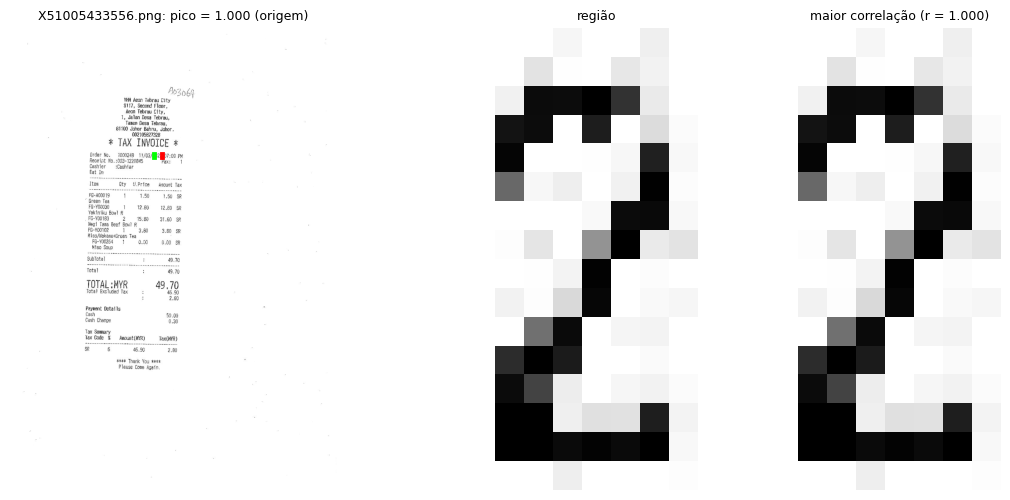

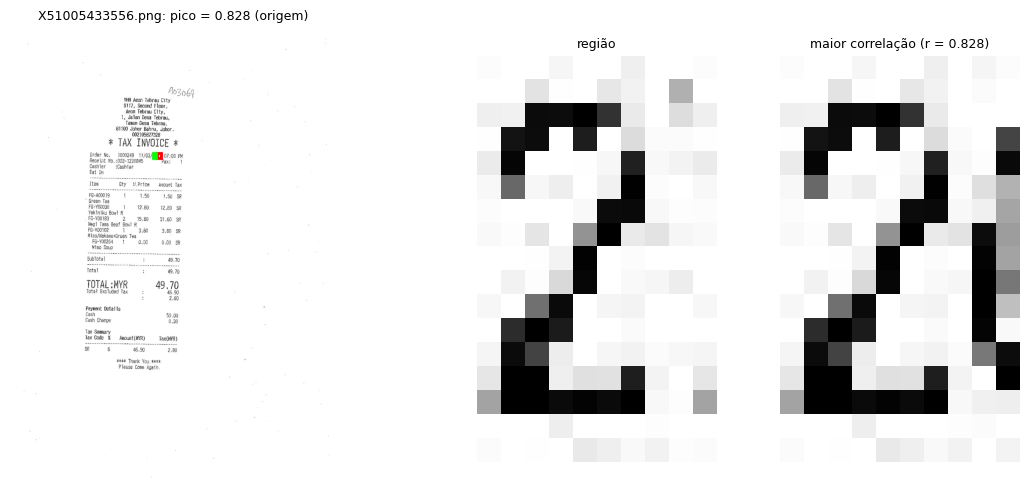

In [3]:
picos = [(s, r, pico, destino) for s in cpi["test"] for r, pico, destino in locate_peaks(s)
         if r.modification and "CPI" in r.modification]
acerto = next(p for p in picos if p[3] == "origem" and p[2] > 0.99)
falha = next(p for p in picos if p[2] < 0.9)

for s, r, pico, destino in (acerto, falha):
    visualize_copy_move(s.image_path, r.bbox, title=f"{s.image_path.name}: pico = {pico:.3f} ({destino})")
    plt.show()

**Interpretação.** Os dois exemplos vêm do mesmo recibo, em que o mesmo dígito aparece em duas regiões CPI. No primeiro, a caixa anotada envolve só o dígito, e o trecho de maior correlação, na origem, é idêntico pixel a pixel (r = 1,000). No segundo, a caixa inclui uma faixa à direita do dígito; na origem, essa faixa contém parte do caractere vizinho, e a correlação cai para 0,828, embora o pico continue no lugar certo. Caixas maiores que o trecho colado reduzem a correlação, o que explica parte das cópias abaixo do limiar.

## 3. Escolha do limiar no `val`

A decisão "existe uma cópia quase exata" exige um limiar para o pico de correlação. Para não ajustar o método no conjunto de teste, o limiar é escolhido no `val`. Em cada imagem com CPI, calcula-se o maior pico entre as regiões modificadas e o pico de uma região de controle com texto, do mesmo tamanho, na mesma imagem. O limiar escolhido é o que maximiza o índice de Youden, J = TPR − FPR, em que TPR é a fração de imagens cuja região CPI tem pico acima do limiar e FPR é a fração de controles acima do limiar.

imagens: 26 | limiar = 0.979 | TPR = 61.5% | FPR = 3.8%
mediana do pico: região CPI = 0.997 | controle = 0.855


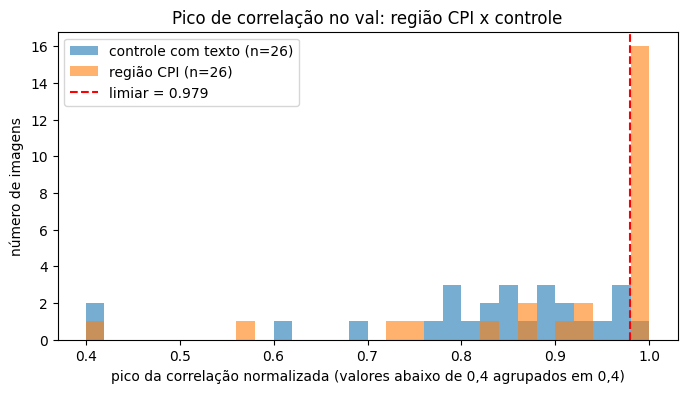

In [4]:
random.seed(42)  # sorteio das regiões de controle
val_scores = [copy_move_region_score(s.image_path, s.regions) for s in cpi["val"]]
val_scores = [(a, b) for a, b in val_scores if a is not None and b is not None]
pico_cpi = [a for a, _ in val_scores]
pico_controle = [b for _, b in val_scores]

candidatos = np.round(np.arange(0.900, 1.0, 0.001), 3)
limiar, tpr, fpr = youden_threshold(pico_cpi, pico_controle, candidatos)
print(f"imagens: {len(val_scores)} | limiar = {limiar:.3f} | TPR = {tpr:.1%} | FPR = {fpr:.1%}")
print(f"mediana do pico: região CPI = {np.median(pico_cpi):.3f} | controle = {np.median(pico_controle):.3f}")

bins = np.arange(0.40, 1.0001, 0.02)
plt.figure(figsize=(8, 4))
plt.hist(np.clip(pico_controle, 0.40, 1.0), bins=bins, alpha=0.6, label=f"controle com texto (n={len(pico_controle)})")
plt.hist(np.clip(pico_cpi, 0.40, 1.0), bins=bins, alpha=0.6, label=f"região CPI (n={len(pico_cpi)})")
plt.axvline(limiar, color="red", linestyle="--", label=f"limiar = {limiar:.3f}")
plt.xlabel("pico da correlação normalizada (valores abaixo de 0,4 agrupados em 0,4)")
plt.ylabel("número de imagens")
plt.title("Pico de correlação no val: região CPI x controle")
plt.legend()
plt.show()

**Interpretação.** No `val`, a mediana do pico é 0,997 nas regiões CPI e 0,855 nos controles com texto. O limiar que maximiza J é 0,979: com ele, 61,5% das imagens com CPI ficam acima do limiar (TPR) e 3,8% dos controles (FPR, 1 de 26). O histograma mostra que a maior parte das regiões CPI se concentra perto de 1, mas uma parte fica espalhada entre 0,4 e 0,95, sobreposta aos controles; essas cópias não são separáveis por nenhum limiar.

## 4. Avaliação no `test`

Com o limiar fixado no `val`, a avaliação usa a mesma função dos notebooks anteriores. Há acerto quando o pico da região modificada é maior ou igual ao limiar. A linha de base nula usa 20 pseudo-regiões de texto por imagem: a taxa de acaso é a fração delas com pico acima do limiar, ou seja, a taxa de alarme falso em texto autêntico. A avaliação é feita separadamente para as imagens com CPI e para as demais.

In [5]:
acima_do_limiar = lambda sin, sout: sin >= limiar

resultados = {
    "Copy-move, imagens com CPI (test)": evaluate_region_technique(cpi["test"], copy_move_region_score, acima_do_limiar),
    "Copy-move, imagens sem CPI (test)": evaluate_region_technique(sem_cpi["test"], copy_move_region_score, acima_do_limiar),
}
print(format_results_table(resultados))

# Imagens sem CPI que dispararam: quais tipos de adulteração elas têm
for s in sem_cpi["test"]:
    pico, _ = copy_move_region_score(s.image_path, s.regions)
    if pico is not None and pico >= limiar:
        print(f"{s.image_path.name}: pico = {pico:.3f} | tipos: {s.tamper_types}")


| técnica/configuração | acerto real (IC 95%) | acaso (média ± desvio) [IC Wilson 95%] | n_real | n_null | exclusões |
|---|---|---|---|---|---|
| Copy-move, imagens com CPI (test) | 81.5% [63.3%, 91.8%] | 10.1% ± 12.8% [7.8%, 12.9%] | 27 | 538 | text_mask_failed=0, real_region_failed=0, few_valid_pseudo=0 |
| Copy-move, imagens sem CPI (test) | 28.6% [8.2%, 64.1%] | 3.6% ± 7.5% [1.5%, 8.1%] | 7 | 140 | text_mask_failed=0, real_region_failed=1, few_valid_pseudo=0 |


X51005447851.png: pico = 1.000 | tipos: ['IMI']


X51008123447.png: pico = 1.000 | tipos: ['IMI']


**Interpretação.** Nas imagens com CPI, o acerto é de 81,5% (22 de 27), contra 10,1% ± 12,8% de alarme falso nas pseudo-regiões de texto autêntico. Como no notebook 02, o intervalo de Wilson do acaso trata as 20 pseudo-regiões de cada imagem como independentes e fica estreito demais; o desvio entre imagens é a medida de variação mais adequada. O acerto no `test` é maior que o TPR do `val` (61,5%), mas, com 27 e 26 imagens, os intervalos são largos, e a diferença deve ser lida com cautela. A taxa de acaso no `test` (10,1%) também é maior que o FPR do `val` (3,8%): o limiar escolhido no `val` gera mais alarmes falsos do que o estimado.

Nas imagens sem CPI, 2 de 7 disparam, contra 3,6% de acaso. As duas têm apenas adulterações do tipo IMI (caixa de texto imitando a fonte) e pico igual a 1,000. Uma explicação possível é que a ferramenta de texto desenha caracteres repetidos de forma idêntica, sem o ruído da digitalização; nesse caso, a correlação normalizada detecta qualquer repetição exata de pixels, e não apenas o copiar e colar. Essa hipótese não foi verificada.

## 5. Para onde aponta o pico

Além de indicar se existe uma cópia, o pico de correlação aponta de onde ela pode ter vindo. Para cada região CPI do `test`, verifica-se se o ponto de maior correlação cai sobre a área de origem anotada, sobre outra região modificada (outra cópia do mesmo trecho), fora das anotações, ou se a imagem não tem origem anotada.

In [6]:
destinos = [destino for _, _, _, destino in picos]
print(f"regiões CPI: {len(destinos)}")
print(dict(Counter(destinos)))

regiões CPI: 76
{'origem': 34, 'outra região modificada': 18, 'fora das anotações': 12, 'sem origem anotada': 12}


**Interpretação.** Das 76 regiões CPI, 34 têm o pico sobre a origem anotada e 18 sobre outra região modificada. No segundo caso, o mesmo trecho foi colado em mais de um lugar, e a cópia mais parecida é outra cópia, e não a origem. Somadas, 52 das 64 regiões com origem anotada (81%) apontam para uma área anotada. Os 12 picos fora das anotações podem ser repetições naturais do texto ou cópias não anotadas; isso não foi verificado.

## 6. Conclusão

**Hipótese.** Uma região copiada de outro ponto do mesmo documento tem, nesse ponto, um par quase idêntico, e a correlação normalizada com ele fica próxima de 1; texto autêntico repetido fica abaixo disso. No `val`, a mediana do pico é 0,997 nas regiões CPI e 0,855 nos controles, o que confirma a hipótese para a maior parte das cópias.

**Resultado.** Com o limiar de 0,979, escolhido no `val` pelo índice de Youden, o copy-move acerta 81,5% das imagens com CPI do `test` (IC 95%: 63,3% a 91,8%), contra 10,1% de alarme falso em texto autêntico. Em 52 das 64 regiões CPI com origem anotada, o pico aponta para a origem ou para outra cópia do mesmo trecho.

**Limitações.**
- A avaliação usa as caixas anotadas: ela mede se a região modificada tem uma cópia quase exata, e não se o método encontra a região sem as anotações. Uma busca cega, comparando os trechos da imagem entre si, não foi feita.
- Parte das cópias fica abaixo do limiar (38,5% das imagens com CPI no `val`). Caixas maiores que o trecho colado e cópias retocadas depois de coladas reduzem a correlação.
- O método reage a qualquer repetição exata de pixels: as duas imagens sem CPI que dispararam têm adulterações do tipo IMI.
- A taxa de alarme falso no `test` (10,1%) ficou acima do FPR estimado no `val` (3,8%).

**Papel no pipeline.** Entre as três técnicas, o copy-move é a única específica para o tipo de adulteração mais frequente do dataset. Ele entra como evidência: uma região com cópia quase exata em outro ponto do documento é uma indicação forte de CPI, e o ponto de maior correlação indica a origem provável.

## 7. Busca cega: escolha dos parâmetros no `val`

As seções anteriores medem o copy-move só dentro das regiões anotadas. A busca cega não usa as anotações: procura, em toda a imagem, pares de componentes de texto com correlação alta.

**Método.** Cada imagem é reduzida para largura de 1000 px (proporção preservada), para que caracteres de digitalizações de resoluções diferentes tenham tamanho comparável. Sobre a máscara de Otsu, cada componente conexo de texto com lado entre `MIN_SIDE` e 60 px é uma caixa candidata. Caixas de mesmo tamanho são comparadas entre si pela correlação normalizada. Um par é mantido se a correlação for maior ou igual ao limiar e se os centros estiverem a pelo menos 8 px.

**Por que componentes, e não uma grade de patches.** Com uma grade de passo fixo, a origem de uma cópia cai desalinhada da grade. Medido nas origens anotadas do `test`, um deslocamento de 6 px reduz a mediana da correlação de 1,000 para 0,928, e só 36% passam de 0,979. Um componente de texto tem o contorno do caractere, então sua cópia tem a mesma caixa.

**Parâmetros.** O tamanho mínimo do componente (`MIN_SIDE`) e o limiar são escolhidos no `val`, pelo critério J = taxa de imagens com CPI que têm algum par − taxa de imagens autênticas que têm algum par. Em caso de empate, vence a maior cobertura de regiões CPI. O `test` não é usado nesta escolha.

In [7]:
from copy_move import blind_copy_move_for_path, candidate_boxes, filter_pairs, region_covered

MIN_SIDES = (6, 10)
THRESHOLDS = (0.90, 0.92, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99)
FLOOR = 0.90  # pares abaixo deste valor não são guardados; os limiares acima são aplicados depois

val_all = [s for s in load_dataset(DATASET_ROOT, "val") if s.image_path.exists()]
cpi_val = [s for s in val_all if s.is_tampered and s.regions and "CPI" in s.tamper_types]
aut_val = [s for s in val_all if not s.is_tampered]

val_pairs = {(s.image_path.name, ms): blind_copy_move_for_path(s.image_path, FLOOR, min_side=ms)[0]
             for ms in MIN_SIDES for s in val_all}

grade = []
for ms in MIN_SIDES:
    for th in THRESHOLDS:
        tpr = sum(len(filter_pairs(val_pairs[(s.image_path.name, ms)], th)) > 0 for s in cpi_val) / len(cpi_val)
        fpr = sum(len(filter_pairs(val_pairs[(s.image_path.name, ms)], th)) > 0 for s in aut_val) / len(aut_val)
        cobertas = total = 0
        for s in cpi_val:
            boxes = candidate_boxes(filter_pairs(val_pairs[(s.image_path.name, ms)], th))
            for r in s.regions:
                if r.is_original_area is True or not (r.modification and "CPI" in r.modification):
                    continue
                total += 1
                cobertas += region_covered(r.bbox, boxes)
        grade.append({"min_side": ms, "th": th, "tpr": tpr, "fpr": fpr, "J": tpr - fpr,
                      "cov": cobertas / total})

print("min_side | limiar | TPR_img | FPR_img |    J    | regiões CPI cobertas")
for g in grade:
    print(f"{g['min_side']:8} | {g['th']:.2f}   | {g['tpr']:6.1%} | {g['fpr']:6.1%} | {g['J']:+.3f} | {g['cov']:.1%}")

escolhido = max(grade, key=lambda g: (g["J"], g["cov"]))
MIN_SIDE, TH = escolhido["min_side"], escolhido["th"]
print(f"\nescolhido no val: MIN_SIDE={MIN_SIDE}, limiar={TH:.2f}")

aviso: 1 imagens listadas em val.txt e ausentes de val/ foram ignoradas: ['X51006619709.png']
aviso: 1 regiões marcadas como área original mas com modificação real (val)


min_side | limiar | TPR_img | FPR_img |    J    | regiões CPI cobertas
       6 | 0.90   | 100.0% |  98.1% | +0.019 | 22.4%
       6 | 0.92   | 100.0% |  97.5% | +0.025 | 18.4%
       6 | 0.94   |  96.2% |  94.3% | +0.018 | 17.1%
       6 | 0.95   |  96.2% |  90.6% | +0.056 | 17.1%
       6 | 0.96   |  96.2% |  84.3% | +0.119 | 17.1%
       6 | 0.97   |  84.6% |  74.2% | +0.104 | 13.2%
       6 | 0.98   |  65.4% |  62.3% | +0.031 | 10.5%
       6 | 0.99   |  34.6% |  15.1% | +0.195 | 7.9%
      10 | 0.90   |  96.2% |  87.4% | +0.087 | 22.4%
      10 | 0.92   |  92.3% |  84.9% | +0.074 | 18.4%
      10 | 0.94   |  92.3% |  81.1% | +0.112 | 17.1%
      10 | 0.95   |  88.5% |  76.7% | +0.117 | 17.1%
      10 | 0.96   |  84.6% |  69.2% | +0.154 | 17.1%
      10 | 0.97   |  69.2% |  61.6% | +0.076 | 13.2%
      10 | 0.98   |  50.0% |  45.9% | +0.041 | 10.5%
      10 | 0.99   |  26.9% |  10.7% | +0.162 | 7.9%

escolhido no val: MIN_SIDE=6, limiar=0.99


## 8. Avaliação no `test`

Com `MIN_SIDE` e o limiar escolhidos no `val`, a busca é aplicada uma única vez a todas as imagens do `test`. As métricas são:

- **Nível de imagem:** taxa de imagens com CPI em que a busca acha pelo menos um par (sensibilidade) e taxa de imagens autênticas com algum par (falso alarme).
- **Nível de região:** fração das regiões CPI anotadas cobertas por uma caixa candidata, com cobertura definida como a fração da área da região anotada que a caixa cobre, e cobertura de pelo menos 50%. A caixa anotada é uma moldura larga em torno dos caracteres alterados; o IoU penalizaria essa folga, enquanto a cobertura pergunta se a busca atinge a área alterada. A caixa candidata pode ser a origem ou o destino da cópia, porque a busca não sabe qual é qual.

Imagens autênticas com par não são necessariamente falsos alarmes de cópia: o texto legítimo também se repete (dígitos, letras do mesmo tipo). A última métrica mede quantos pares são cópias exatas (correlação de pelo menos 0,9999).

In [8]:
test_all = [s for s in load_dataset(DATASET_ROOT, "test") if s.image_path.exists()]
cpi_test = [s for s in test_all if s.is_tampered and s.regions and "CPI" in s.tamper_types]
sem_cpi_test = [s for s in test_all if s.is_tampered and s.regions and "CPI" not in s.tamper_types]
aut_test = [s for s in test_all if not s.is_tampered]

test_pairs = {s.image_path.name: filter_pairs(blind_copy_move_for_path(s.image_path, FLOOR, min_side=MIN_SIDE)[0], TH)
              for s in test_all}

sens_img = sum(len(test_pairs[s.image_path.name]) > 0 for s in cpi_test) / len(cpi_test)
falso_alarme = sum(len(test_pairs[s.image_path.name]) > 0 for s in aut_test) / len(aut_test)
sem_cpi_img = sum(len(test_pairs[s.image_path.name]) > 0 for s in sem_cpi_test) / len(sem_cpi_test)

cobertas = total = 0
for s in cpi_test:
    boxes = candidate_boxes(test_pairs[s.image_path.name])
    for r in s.regions:
        if r.is_original_area is True or not (r.modification and "CPI" in r.modification):
            continue
        total += 1
        cobertas += region_covered(r.bbox, boxes)

print(f"test | MIN_SIDE={MIN_SIDE} | limiar={TH:.2f}")
print(f"imagens com CPI com algum par (sensibilidade):  {sens_img:.1%}  ({sum(len(test_pairs[s.image_path.name]) > 0 for s in cpi_test)}/{len(cpi_test)})")
print(f"imagens autênticas com algum par (falso alarme): {falso_alarme:.1%}  ({sum(len(test_pairs[s.image_path.name]) > 0 for s in aut_test)}/{len(aut_test)})")
print(f"imagens com outros tipos com algum par:          {sem_cpi_img:.1%}  ({sum(len(test_pairs[s.image_path.name]) > 0 for s in sem_cpi_test)}/{len(sem_cpi_test)})")
print(f"regiões CPI cobertas por caixa candidata (>=50%): {cobertas}/{total} = {cobertas / total:.1%}")

com_par = [s for s in aut_test if test_pairs[s.image_path.name]]
pares_autenticas = [p for s in com_par for p in test_pairs[s.image_path.name]]
exatas = sum(1 for _, _, r in pares_autenticas if r >= 0.9999)
print(f"\nautênticas com algum par: {len(com_par)} | pares por imagem (mediana): {np.median([len(test_pairs[s.image_path.name]) for s in com_par]):.0f}")
print(f"pares em autênticas: {len(pares_autenticas)} | cópias exatas (r >= 0,9999): {exatas} ({exatas / max(len(pares_autenticas), 1):.0%})")

test | MIN_SIDE=6 | limiar=0.99
imagens com CPI com algum par (sensibilidade):  33.3%  (9/27)
imagens autênticas com algum par (falso alarme): 17.5%  (32/183)
imagens com outros tipos com algum par:          25.0%  (2/8)
regiões CPI cobertas por caixa candidata (>=50%): 8/76 = 10.5%

autênticas com algum par: 32 | pares por imagem (mediana): 1
pares em autênticas: 62 | cópias exatas (r >= 0,9999): 2 (3%)


## 9. Conclusão da busca cega

**Resultado.** Com tamanho mínimo de componente de 6 px e limiar de 0,99, escolhidos no `val`, a busca acha pelo menos um par em 33% das imagens com CPI do `test` (9 de 27) e em 17,5% das autênticas (32 de 183). Na escala de imagem, a precisão é de 9 em 41, cerca de 22%. Das 76 regiões CPI, 10,5% (8) são cobertas por uma caixa candidata.

**Causa do falso alarme.** Dos 62 pares encontrados em imagens autênticas, apenas 2 (3%) são cópias exatas (correlação de pelo menos 0,9999). Os demais são caracteres repetidos (dígitos e letras da mesma fonte), com correlação entre 0,99 e 0,9999. Um limiar não separa esses casos de uma cópia.

**Causa da perda.** Nas imagens com CPI, a busca só compara componentes de mesmo tamanho. Uma cópia fundida com caracteres vizinhos, ou um trecho copiado com outro recorte, não tem caixa igual à original e não é encontrada.

**Leitura.** A busca cega, como implementada, não serve como triagem: marca cerca de uma em cada seis imagens autênticas e deixa passar dois terços das imagens com CPI. A seção 4 continua válida, porque mede a separação entre cópias e texto comum quando a região é conhecida (medianas de 0,997 contra 0,855). Sem as anotações, essa separação não se mantém. Para o relatório, a afirmação defensável é: o copy-move identifica cópias quando a região suspeita é indicada, mas a busca automática gera muitos falsos alarmes por causa de texto repetido.

**Não feito por falta de tempo.** Verificar a fusão de componentes (por exemplo, janelas de largura variável), e comparar caracteres por conteúdo, com OCR, para descartar repetições de dígitos. Ambos podem reduzir o falso alarme, mas precisariam de avaliação própria.